# 8b. Extension of notebook 8: what if the target real rate is negative?

This notebook **adds** to notebook `8. empirical_claims.ipynb` and replaces nothing in it. The solver, the model inputs and the helper functions are copied verbatim from notebook 8. The one difference is that the $\rho$ bracket search may start below $\rho=r^*$ when the target is negative; $\rho$ must stay positive and above $r^*$.

**Motivation.**
- At the thesis $\rho=0.05$, the 4-state model clears at $r^*=-0.76\%$.
- Notebook 8 found that Argentina's 50-year ex-post real rate is negative: median $-5.1\%$; 1993–2025 median $-3.6\%$.
- So, should the target be a negative real rate? This notebook repeats the notebook-8 test, calibrating $\rho$ so that $r^*$ equals the target, for a range of targets from $+2\%$ down to the data medians.

**What is judged.** For each target:
1. **The calibrated parameter**, $\rho$ (or $\beta=e^{-\rho}$): is it inside the range used in the literature?
2. **Untargeted predictions**, which were not used in the calibration: borrower share, mass at the borrowing limit, the informal/formal consumption ratio, and debt relative to income. These are the moments that could later be compared with household data such as ENGHo or Global Findex.

In [1]:
import os, math, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.sparse import spdiags, eye, bmat, kron, csc_matrix
from scipy.sparse.linalg import spsolve

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "axes.grid": True,
                     "grid.color": "#e8e8e8", "legend.frameon": False})
MODEL_DATA = "data"                                    # repo data folder (lambdas, incomes)
DATA_DIR = os.path.join(MODEL_DATA, "interest_rates")  # interest-rate inputs and results of this notebook
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
R_TARGET = 0.02   # needed only as a default argument of the functions copied from notebook 8

In [3]:
I_GRID, AMIN, AMAX = 800, -0.099, 5.0
a = np.linspace(AMIN, AMAX, I_GRID)
da = (AMAX - AMIN) / (I_GRID - 1)

def solve_given_r(r, rho, m, V_init=None, Delta=1000.0, maxit=400):
    z, gamma, tau, theta = m["z"], m["gamma"], m["tau"], m["theta"]
    I, N = len(a), len(z)
    zat = (1 - tau) * z
    zz = np.ones((I, 1)) * zat[None, :]
    aa = np.repeat(a[:, None], N, axis=1)
    R = r + theta[None, :] * (a < 0)[:, None]
    Lam = np.array(m["Lambda"], float).copy()
    np.fill_diagonal(Lam, 0.0); np.fill_diagonal(Lam, -Lam.sum(1))       # enforce row sums = 0
    Asw = kron(csc_matrix(Lam), eye(I), format="csc")
    if V_init is None:
        V = np.maximum(zz + r * aa, 1e-12) ** (1 - gamma) / ((1 - gamma) * rho)
    else:
        V = V_init.copy()
    dVf = np.zeros((I, N)); dVb = np.zeros((I, N)); converged = False
    for it in range(maxit):
        dVf[:-1] = (V[1:] - V[:-1]) / da
        dVf[-1] = np.maximum(zat + r * AMAX, 1e-12) ** (-gamma)
        dVb[1:] = (V[1:] - V[:-1]) / da
        dVb[0] = np.maximum(zat + (r + theta) * AMIN, 1e-12) ** (-gamma)
        cf = np.maximum(dVf, 1e-12) ** (-1 / gamma)
        cb = np.maximum(dVb, 1e-12) ** (-1 / gamma)
        ssf = zz + R * aa - cf; ssb = zz + R * aa - cb; c0 = zz + R * aa
        If = (ssf > 1e-14).astype(float); Ib = (ssb < -1e-14).astype(float); I0 = 1 - If - Ib
        c = cf * If + cb * Ib + c0 * I0
        util = np.maximum(c, 1e-12) ** (1 - gamma) / (1 - gamma)
        X = -np.minimum(ssb, 0) / da
        Y = -np.maximum(ssf, 0) / da + np.minimum(ssb, 0) / da
        Zc = np.maximum(ssf, 0) / da
        blocks = [spdiags(Y[:, j], 0, I, I) + spdiags(X[1:, j], -1, I, I)
                  + spdiags(np.hstack(([0.0], Zc[:-1, j])), 1, I, I) for j in range(N)]
        A = bmat([[blocks[i] if i == j else None for j in range(N)] for i in range(N)], format="csc") + Asw
        if np.max(np.abs(np.asarray(A.sum(axis=1)).ravel())) > 1e-7:
            # Same check as notebooks 4/5; here the point is flagged invalid instead of aborting
            return dict(V=V, c=c, g=None, adot=None, S=np.nan, valid=False, iters=it + 1)
        B = (1 / Delta + rho) * eye(N * I, format="csc") - A
        Vn = spsolve(B, util.T.ravel() + V.T.ravel() / Delta).reshape(N, I).T
        diff = np.max(np.abs(Vn - V)); V = Vn
        if diff < 1e-6:
            converged = True; break
    AT = A.T.tolil(); b = np.zeros(N * I); AT[0, :] = 0; AT[0, 0] = 1; b[0] = 1
    g = spsolve(AT.tocsr(), b).reshape(N, I).T
    g /= g.sum() * da
    valid = converged and (g.min() * da > -1e-8)
    return dict(V=V, c=c, g=g, adot=zz + R * aa - c, S=float((g * a[:, None]).sum() * da),
                valid=valid, iters=it + 1)

def find_equilibrium(rho, m, rmin, rmax, r0=0.03, tol_S=1e-5, max_iter=100):
    # Same bisection rule as notebooks 4/5: S>0 -> lower r, S<0 -> raise r
    r, V = r0, None
    for _ in range(max_iter):
        out = solve_given_r(r, rho, m, V_init=V)
        if out["S"] > tol_S:   rmax, r = r, 0.5 * (r + rmin)
        elif out["S"] < -tol_S: rmin, r = r, 0.5 * (r + rmax)
        else: return r, out, True
        V = out["V"]
    return r, out, False

In [4]:
def read_generator(fname, order):
    # Read a generator CSV exported by the R scripts and reorder rows/cols by state label
    df = pd.read_csv(os.path.join(MODEL_DATA, fname), index_col=0)
    df.index = df.index.str.strip(); df.columns = df.columns.str.strip()
    return df.loc[order, order].to_numpy(float)

L2_DATA = read_generator("lambda_matrix_2state_datadriven.csv", ["I", "F"])
TOTAL_HAZARD_2S = L2_DATA[0, 1] + L2_DATA[1, 0]        # lam_IF + lam_FI from EPH
print(f"2-state data generator: lam_IF={L2_DATA[0,1]:.6f}, lam_FI={L2_DATA[1,0]:.6f}, total={TOTAL_HAZARD_2S:.6f}")

def lambda_2state(eta, s=TOTAL_HAZARD_2S):
    # row = from, col = to ; states (I, F); stationary informal share = eta (same split as notebook 4)
    return np.array([[0.0, (1 - eta) * s], [eta * s, 0.0]])

ORDER4 = ["IH", "IL", "FH", "FL"]   # model order used in notebook 5
LAMBDA4_ETA42 = read_generator("lambda_matrix_4state_datadriven.csv", ORDER4)       # thesis Table 3
LAMBDA4_ETA20 = read_generator("lambda_matrix_4state_benchmark_eta20.csv", ORDER4)  # thesis Table 2

def model_2state(eta=0.42, gamma_I=0.30, tau_F=0.19):
    return dict(name="2-state", labels=["I", "F"], informal=[0], formal=[1],
                z=np.array([0.418, 1.0]), gamma=np.array([gamma_I, 0.15]),
                tau=np.array([0.0, tau_F]), theta=np.array([0.02, 0.0]), Lambda=lambda_2state(eta))

def model_4state(eta=0.42, tau_FH=0.19, tau_FL=0.05):
    L = {0.42: LAMBDA4_ETA42, 0.20: LAMBDA4_ETA20}[eta]
    return dict(name="4-state", labels=["IH", "IL", "FH", "FL"], informal=[0, 1], formal=[2, 3],
                z=np.array([0.82979213, 0.219700297, 1.0, 0.321119145]),
                gamma=np.array([0.30, 0.30, 0.15, 0.15]),
                tau=np.array([0.0, 0.0, tau_FH, tau_FL]), theta=np.array([0.02, 0.02, 0.0, 0.0]), Lambda=L)

def stationary(L):
    L = np.array(L, float).copy(); np.fill_diagonal(L, 0); np.fill_diagonal(L, -L.sum(1))
    w, v = np.linalg.eig(L.T); p = np.real(v[:, np.argmin(np.abs(w))]); return p / p.sum()

for eta in (0.20, 0.42):
    p = stationary(model_4state(eta)["Lambda"])
    print(f"4-state eta={eta}: stationary (IH,IL,FH,FL) = {np.round(p,4)}, informal = {p[:2].sum():.4f}, "
          f"phi = IH/(IH+IL) = {p[0]/p[:2].sum():.3f}")

2-state data generator: lam_IF=0.684364, lam_FI=0.229618, total=0.913981
4-state eta=0.2: stationary (IH,IL,FH,FL) = [0.0368 0.1632 0.556  0.244 ], informal = 0.2000, phi = IH/(IH+IL) = 0.184
4-state eta=0.42: stationary (IH,IL,FH,FL) = [0.0772 0.3428 0.4031 0.1769], informal = 0.4200, phi = IH/(IH+IL) = 0.184


In [5]:
def bracket_rho(m, r_target, step=0.005, rho_max=0.30):
    # Walk up from just above r_target: lo = last VALID rho with S>0, hi = first rho with S<0
    lo, rho = None, r_target + step
    while rho <= rho_max:
        out = solve_given_r(r_target, rho, m)
        if out["valid"] and out["S"] > 0: lo = rho
        elif out["valid"] and out["S"] < 0:
            assert lo is not None, "no valid rho with S>0 below the root"
            return lo, rho
        rho += step
    raise RuntimeError("root not bracketed")

def calibrate_rho(m, r_target=R_TARGET, tol=1e-7, max_iter=60):
    lo, hi = bracket_rho(m, r_target)
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi); out = solve_given_r(r_target, mid, m)
        assert out["valid"], f"invalid solve at rho={mid}"
        if out["S"] > 0: lo = mid
        else: hi = mid
        if hi - lo < tol: break
    return 0.5 * (lo + hi)

In [6]:
def moments(m, out, r):
    g, c, adot = out["g"], out["c"], out["adot"]
    mass = g.sum(0) * da
    inf, frm = m["informal"], m["formal"]
    row = {"r* %": 100 * r,
           "borrowers mass (a<0)": (g[a < 0].sum()) * da,
           "mass at borrowing limit (first grid pt)": g[0].sum() * da,
           "informal: share borrowing": g[a < 0][:, inf].sum() * da / mass[inf].sum(),
           "formal: share borrowing": g[a < 0][:, frm].sum() * da / mass[frm].sum(),
           "informal mean wealth": (g[:, inf] * a[:, None]).sum() * da / mass[inf].sum(),
           "formal mean wealth": (g[:, frm] * a[:, None]).sum() * da / mass[frm].sum(),
           "informal mean consumption": (g[:, inf] * c[:, inf]).sum() * da / mass[inf].sum(),
           "formal mean consumption": (g[:, frm] * c[:, frm]).sum() * da / mass[frm].sum(),
           "gross debt / mean after-tax income": (g * np.maximum(-a, 0)[:, None]).sum() * da
                                                 / (mass * (1 - m["tau"]) * m["z"]).sum()}
    for j, lab in enumerate(m["labels"]):
        row[f"[{lab}] mass"] = mass[j]
        row[f"[{lab}] mean wealth"] = (g[:, j] * a).sum() * da / mass[j]
        row[f"[{lab}] share borrowing"] = g[a < 0, j].sum() * da / mass[j]
    return row

## Step 0. A numerical fix for $r \le 0$ (initial guess only)

The solver in notebooks 4, 5 and 8 starts the value-function iteration from $V_0=u(\tilde y + r a)/\rho$.
- For $r\le 0$ this guess is flat or decreasing in $a$. The first upwind step then breaks the generator, and the solve fails at iteration 1 for **every** $\rho$.
- Notebook 8 only reached $r^*=-0.76\%$ because its bisection warm-starts from a positive-$r$ solution.
- This is a property of the starting point, not of the economics.

Here the solver is unchanged. We only pass it a different starting point, $V_0=u(\tilde y+\rho a)/\rho$, which is increasing and concave for any $r$. The HJB has a unique fixed point, so the converged solution must not depend on $V_0$. The next cell checks this at $r=2\%$ against the notebook-8 guess.

**Continuation.** At negative $r$, even this guess can fail when $\rho$ is far from a solved point. Two standard remedies are used, and neither changes the fixed point:
1. warm-start each $\rho$ from the last valid solution;
2. if that still fails, retry with a smaller implicit step ($\Delta=50$, up to 3000 iterations).

$S=a_{\min}\approx-0.099$ means the whole population sits at the borrowing limit. That is a genuine corner of the model, not a failed solve.

In [7]:
def guess_V(m, rho):
    zat = (1 - m["tau"]) * m["z"]
    c0 = np.maximum(zat[None, :] + rho * a[:, None], 1e-12)
    return c0 ** (1 - m["gamma"]) / ((1 - m["gamma"]) * rho)

def solve_r(r, rho, m, V_init=None):
    return solve_given_r(r, rho, m, V_init=guess_V(m, rho) if V_init is None else V_init)

def solve_cont(r, rho, m, V_init=None):
    # solve with warm start; if invalid, retry with a smaller implicit step (same fixed point)
    out = solve_r(r, rho, m, V_init=V_init)
    if not out["valid"]:
        out = solve_given_r(r, rho, m, V_init=guess_V(m, rho) if V_init is None else V_init,
                            Delta=50.0, maxit=3000)
    return out

def find_equilibrium_g(rho, m, rmin, rmax, r0, V0=None, tol_S=1e-5, max_iter=100):
    # notebook-8 bisection; only the starting value function and the fallback differ
    r, V = r0, V0
    for _ in range(max_iter):
        out = solve_cont(r, rho, m, V_init=V)
        if not out["valid"]: return r, out, False
        if out["S"] > tol_S:   rmax, r = r, 0.5 * (r + rmin)
        elif out["S"] < -tol_S: rmin, r = r, 0.5 * (r + rmax)
        else: return r, out, True
        V = out["V"]
    return r, out, False

chk = []
for mk in (model_2state, model_4state):
    m = mk(0.42)
    o_old = solve_given_r(0.02, 0.05, m); o_new = solve_r(0.02, 0.05, m)
    chk.append({"model": m["name"], "S old guess": o_old["S"], "S new guess": o_new["S"],
                "max |V_old - V_new|": np.abs(o_old["V"] - o_new["V"]).max(),
                "valid at r=0, rho=0.05 (old guess)": solve_given_r(0.0, 0.05, m)["valid"],
                "valid at r=0, rho=0.05 (new guess)": solve_r(0.0, 0.05, m)["valid"]})
pd.DataFrame(chk)

,model,S old guess,S new guess,max |V_old - V_new|,"valid at r=0, rho=0.05 (old guess)","valid at r=0, rho=0.05 (new guess)"
0,2-state,0.023759,0.023759,5.392309e-11,False,True
1,4-state,0.158760,0.158760,3.023413e-10,False,True


## Step 1. Targets

The targets include 2% (notebook 8), zero, and negative values. Two of them are data moments computed in notebook 8 from `data/interest_rates/argentina_real_rate_summary.csv`: the 1993–2025 median and the 1976–2025 median of the ex-post real short-term rate.

In [8]:
summary = pd.read_csv(os.path.join(DATA_DIR, "argentina_real_rate_summary.csv"))
med_50y = summary.query("series == 'short-term rate' and window == '1976-2025'")["real median %"].item() / 100
med_93 = summary.query("series == 'short-term rate' and window == '1993-2025'")["real median %"].item() / 100
TARGETS = {"+2% (notebook 8)": 0.02, "0%": 0.0, "-1%": -0.01, "-2%": -0.02,
           f"1993-2025 median ({100*med_93:.2f}%)": med_93, f"1976-2025 median ({100*med_50y:.2f}%)": med_50y}
TARGETS

{'+2% (notebook 8)': 0.02,
 '0%': 0.0,
 '-1%': -0.01,
 '-2%': -0.02,
 '1993-2025 median (-3.56%)': -0.035623287852616814,
 '1976-2025 median (-5.12%)': -0.05122231674678767}

## Step 2. Calibrate $\rho$ to each target in each model

- `bracket_rho_pos` is notebook 8's `bracket_rho`, except that the walk starts at $\max(r^*,0)$ plus a step, because $\rho$ must be positive.
- A point counts as invalid, exactly as in notebook 8, when wealth runs into $a_{\max}$ (HJB not converged or improper generator). If no valid $\rho$ hits the target, the table reports it rather than guessing.
- Each calibration is then verified by re-solving the full equilibrium.
- Every solve uses the Step 0 initial guess and continuation.

In [9]:
def bracket_rho_pos(m, r_target, step=0.0025, rho_max=0.30):
    # Walk rho upward with continuation; lo = last valid rho with S>0, hi = first valid rho with S<0
    lo, V_lo, V, rho = None, None, None, max(r_target, 0.0) + step
    while rho <= rho_max:
        out = solve_cont(r_target, rho, m, V_init=V)
        if out["valid"]:
            V = out["V"]
            if out["S"] > 0: lo, V_lo = rho, V
            elif out["S"] < 0: return lo, rho, V_lo
        rho += step
    return lo, None, V_lo

def calibrate_rho_pos(m, r_target, tol=1e-7, max_iter=60):
    lo, hi, V = bracket_rho_pos(m, r_target)
    if hi is None: return np.nan, "not bracketed", None
    if lo is None:
        return np.nan, f"S<0 already at the smallest rho tried ({hi:.4f}): no rho>0 reaches this r*", None
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi); out = solve_cont(r_target, mid, m, V_init=V)
        if not out["valid"]: return np.nan, f"invalid solve at rho={mid:.4f}", None
        V = out["V"]
        if out["S"] > 0: lo = mid
        else: hi = mid
        if hi - lo < tol: break
    return 0.5 * (lo + hi), "ok", V

rows, sols = [], {}
for lab, rt in TARGETS.items():
    for mk in (model_2state, model_4state):
        m = mk(0.42)
        rho, status, V_cal = calibrate_rho_pos(m, rt)
        row = {"target": lab, "r* target %": 100 * rt, "model": m["name"], "rho": rho, "status": status}
        if status == "ok":
            r, out, ok = find_equilibrium_g(rho, m, rmin=-0.15, rmax=0.10, r0=rt, V0=V_cal)
            row.update({"annual beta": np.exp(-rho), "quarterly beta": np.exp(-rho / 4),
                        "verified r* %": 100 * r, "cleared": ok and out["valid"]})
            sols[(lab, m["name"])] = (m, out, r)
        rows.append(row)
tab_neg = pd.DataFrame(rows)
tab_neg.to_csv(os.path.join(DATA_DIR, "calibration_rho_negative_targets.csv"), index=False)
tab_neg.round(4)

,target,r* target %,model,rho,status,annual beta,quarterly beta,verified r* %,cleared
0,+2% (notebook 8),2.0000,2-state,0.0542,ok,0.9473,0.9866,2.0000,True
1,+2% (notebook 8),2.0000,4-state,0.0780,ok,0.9250,0.9807,2.0000,True
2,0%,0.0000,2-state,0.0340,ok,0.9665,0.9915,0.0000,True
3,0%,0.0000,4-state,0.0577,ok,0.9439,0.9857,0.0000,True
4,-1%,-1.0000,2-state,0.0240,ok,0.9763,0.9940,-1.0000,True
5,-1%,-1.0000,4-state,0.0476,ok,0.9535,0.9882,-1.0000,True
6,-2%,-2.0000,2-state,0.0139,ok,0.9862,0.9965,-2.0000,True
7,-2%,-2.0000,4-state,0.0375,ok,0.9632,0.9907,-2.0000,True
8,1993-2025 median (-3.56%),-3.5623,2-state,NaN,S<0 already at the smallest rho tried (0.0025)...,NaN,NaN,NaN,NaN
9,1993-2025 median (-3.56%),-3.5623,4-state,0.0217,ok,0.9785,0.9946,-3.5623,True


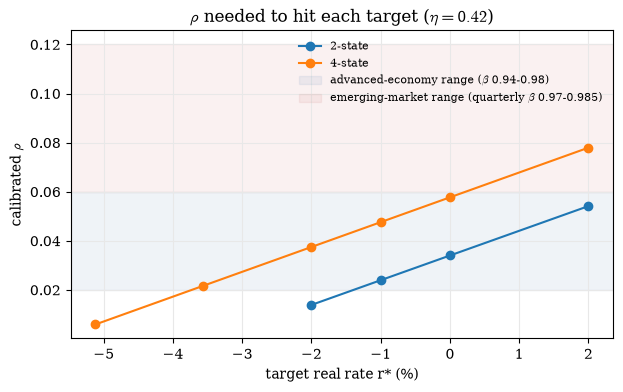

model,2-state,4-state,rho_4s - rho_2s,2-state: rho - r*,4-state: rho - r*
r* target %,,,,,
2.000000,0.0542,0.0780,0.0238,0.0342,0.0580
0.000000,0.0340,0.0577,0.0237,0.0340,0.0577
-1.000000,0.0240,0.0476,0.0237,0.0340,0.0576
-2.000000,0.0139,0.0375,0.0236,0.0339,0.0575
-3.562329,NaN,0.0217,NaN,NaN,0.0573
-5.122232,NaN,0.0059,NaN,NaN,0.0571


In [10]:
piv = tab_neg.pivot(index="r* target %", columns="model", values="rho").sort_index(ascending=False)
piv["rho_4s - rho_2s"] = piv["4-state"] - piv["2-state"]
for mname in ("2-state", "4-state"):
    piv[f"{mname}: rho - r*"] = piv[mname] - piv.index / 100   # impatience gap
piv.to_csv(os.path.join(DATA_DIR, "rho_and_gap_by_target.csv"))
fig, ax = plt.subplots(figsize=(7, 4))
for mname in ("2-state", "4-state"):
    ax.plot(piv.index, piv[mname], "o-", label=mname)
ax.axhspan(0.02, 0.06, color="#3b6ea5", alpha=0.08, label=r"advanced-economy range ($\beta$ 0.94-0.98)")
ax.axhspan(0.06, 0.12, color="#c0504d", alpha=0.08, label=r"emerging-market range (quarterly $\beta$ 0.97-0.985)")
ax.set_xlabel("target real rate r* (%)"); ax.set_ylabel(r"calibrated $\rho$"); ax.legend(fontsize=8)
ax.set_title(r"$\rho$ needed to hit each target ($\eta=0.42$)"); plt.show()
piv.round(4)

## Step 3. Untargeted predictions at each calibration

None of these moments were targeted. They are what each model predicts once it has been forced to match the same $r^*$. They are the natural place to compare with household data later; no such data are used here.

In [11]:
pred = []
for (lab, mname), (m, out, r) in sols.items():
    mo = moments(m, out, r)
    pred.append({"target": lab, "model": mname, "r* %": 100 * r,
                 "borrowers mass": mo["borrowers mass (a<0)"],
                 "mass at borrowing limit": mo["mass at borrowing limit (first grid pt)"],
                 "informal share borrowing": mo["informal: share borrowing"],
                 "formal share borrowing": mo["formal: share borrowing"],
                 "c_informal / c_formal": mo["informal mean consumption"] / mo["formal mean consumption"],
                 "gross debt / income": mo["gross debt / mean after-tax income"]})
pred = pd.DataFrame(pred).sort_values(["model", "r* %"], ascending=[True, False])
pred.to_csv(os.path.join(DATA_DIR, "untargeted_moments_by_target.csv"), index=False)
pred.round(4)

,target,model,r* %,borrowers mass,mass at borrowing limit,informal share borrowing,formal share borrowing,c_informal / c_formal,gross debt / income
0,+2% (notebook 8),2-state,2.0000,0.4911,0.2340,0.8605,0.2235,0.6196,0.0557
2,0%,2-state,0.0000,0.4909,0.2345,0.8613,0.2226,0.6223,0.0557
4,-1%,2-state,-1.0000,0.4907,0.2348,0.8616,0.2222,0.6237,0.0557
6,-2%,2-state,-2.0000,0.4906,0.2350,0.8620,0.2217,0.6251,0.0557
1,+2% (notebook 8),4-state,2.0000,0.5219,0.2191,0.7584,0.3506,0.5509,0.0714
3,0%,4-state,0.0000,0.5220,0.2199,0.7593,0.3502,0.5531,0.0715
5,-1%,4-state,-1.0000,0.5221,0.2204,0.7597,0.3500,0.5542,0.0716
7,-2%,4-state,-2.0000,0.5221,0.2208,0.7602,0.3498,0.5553,0.0716
8,1993-2025 median (-3.56%),4-state,-3.5623,0.5222,0.2214,0.7609,0.3494,0.5570,0.0717
9,1976-2025 median (-5.12%),4-state,-5.1222,0.5223,0.2220,0.7616,0.3491,0.5588,0.0718


## Step 4. Reading the results

**1. What is pinned down is the impatience gap $\rho - r^*$, not $\rho$ itself.**
- Across all targets the gap is almost constant: about $0.034$ in the 2-state model and $0.058$ in the 4-state model.
- The untargeted predictions in Step 3 barely change with the target. Moving $r^*$ and $\rho$ together leaves household behaviour almost unchanged.

**2. For positive or mildly negative targets ($+2\%$ to $-2\%$), both models calibrate with positive $\rho$.**
- The 2-state $\rho$ falls toward very patient values: $\rho=0.014$ ($\beta=0.986$ annual) at $-2\%$.
- The 4-state $\rho$ stays in an ordinary range: $0.038$ to $0.078$.

**3. At the data medians, only the 4-state model can be calibrated.**
- The 1993–2025 median is $-3.6\%$; the 1976–2025 median is $-5.1\%$.
- With a positive discount rate, the 2-state model cannot generate $r^*=-3.6\%$ or $-5.1\%$. Even at $\rho=0.0025$, households already hold too few bonds. Extrapolating its gap, it would need $\rho\approx -0.2\%$ and $-1.7\%$: households valuing the future more than the present, which is not a standard parameter.
- The 4-state model reaches $-3.6\%$ with $\rho=0.022$ ($\beta=0.978$), a textbook value. It reaches $-5.1\%$ with $\rho=0.006$ ($\beta=0.994$), very patient but positive.

**4. So which model has the "strange" parameter depends on the target.**
- **Positive targets:** neither model is strange; the 4-state needs more impatience.
- **The negative ex-post data medians:** the 2-state model needs a negative discount rate, while the 4-state does not.
- The reason is that the 4-state model has more precautionary saving: at the same $\rho$ it wants to hold more bonds, so only a low or negative $r^*$ clears the market. That is the feature that lets it match a negative real rate.

**5. Caveat that decides whether point 3 matters.** It holds only if a negative ex-post real rate is the right counterpart to the model's $r^*$.
- The model's $r^*$ is the equilibrium return on the only risk-free saving vehicle, traded among households. Argentina's negative ex-post peso rates mostly reflect surprise inflation, rate caps and financial repression.
- Argentine households save largely in dollars and real estate, outside peso deposits. A target based on dollar returns would be closer to $0$–$1\%$.
- Points 1–2 apply to that range.

In [12]:
print(piv.round(4).to_string())
print()
print(pred.round(3).to_string(index=False))

model        2-state  4-state  rho_4s - rho_2s  2-state: rho - r*  4-state: rho - r*
r* target %                                                                         
 2.000000     0.0542   0.0780           0.0238             0.0342             0.0580
 0.000000     0.0340   0.0577           0.0237             0.0340             0.0577
-1.000000     0.0240   0.0476           0.0237             0.0340             0.0576
-2.000000     0.0139   0.0375           0.0236             0.0339             0.0575
-3.562329        NaN   0.0217              NaN                NaN             0.0573
-5.122232        NaN   0.0059              NaN                NaN             0.0571

                   target   model   r* %  borrowers mass  mass at borrowing limit  informal share borrowing  formal share borrowing  c_informal / c_formal  gross debt / income
         +2% (notebook 8) 2-state  2.000           0.491                    0.234                     0.861                   0.224            

## Step 5. Fix $\rho$ and $r^*$, free a parameter that can be checked in data

This is notebook 8's Step 11 repeated for every target of Step 1, including the negative data medians. The helper code is copied verbatim from notebook 8. The only change is the solver: it uses the Step 0 initial guess and continuation, which are needed at $r\le 0$.

- $\rho$ is held at the thesis value $0.05$ and $r$ at the target.
- Freed, one at a time: the borrowing limit $a_{\min}$ (thesis $-0.099$) and the informal borrowing premium $\theta_I$ (thesis $0.02$).
- Both are bisected on $S(r^*;\,\cdot\,)=0$, exactly as $\rho$ was in Step 2, and every calibration is verified by re-solving the full equilibrium.
- "Not attainable" means no value on the scan grid makes $S$ change sign: no admissible value of that parameter delivers that $r^*$ at $\rho=0.05$.


In [13]:
from contextlib import contextmanager

RHO_FIX = 0.05          # thesis discount rate, held fixed in this step
AMIN_THESIS = AMIN      # thesis borrowing limit (-0.099)

@contextmanager
def borrowing_limit(amin, n_grid=None):
    # Rebuild the global asset grid with a different a_min (same AMAX); restore it on exit.
    # solve_given_r and moments read a, da, AMIN, I_GRID from the notebook namespace.
    global a, da, AMIN, I_GRID
    saved = (a, da, AMIN, I_GRID)
    I_GRID = I_GRID if n_grid is None else n_grid
    AMIN = amin; a = np.linspace(AMIN, AMAX, I_GRID); da = (AMAX - AMIN) / (I_GRID - 1)
    try:
        yield
    finally:
        a, da, AMIN, I_GRID = saved

def with_theta(m, theta_I):
    # Same model, with the borrowing premium of every informal state set to theta_I
    m = dict(m); th = m["theta"].copy(); th[m["informal"]] = theta_I; m["theta"] = th
    return m

def calibrate_scalar(solve_at, grid, tol=1e-7, max_iter=60, jump_tol=1e-4):
    # Scan the grid for a sign change of S between consecutive valid points, then bisect inside it.
    # If S still differs by more than jump_tol across the final bracket, S jumps over zero
    # (households bunch at a few asset levels): there is no interior root, so none is reported.
    scan = [(p, solve_at(p)) for p in grid]
    ok = [(p, o["S"]) for p, o in scan if o["valid"]]
    for (p0, s0), (p1, s1) in zip(ok, ok[1:]):
        if s0 * s1 < 0:
            lo, hi, s_lo, s_hi = p0, p1, s0, s1
            for _ in range(max_iter):
                mid = 0.5 * (lo + hi); out = solve_at(mid)
                if not out["valid"]: return np.nan, f"invalid solve at {mid:.4f}", scan
                if out["S"] * s0 > 0: lo, s_lo = mid, out["S"]
                else: hi, s_hi = mid, out["S"]
                if abs(hi - lo) < tol: break
            if abs(s_hi - s_lo) > jump_tol:
                return np.nan, f"no root: S jumps from {s_lo:.4f} to {s_hi:.4f} at {0.5*(lo+hi):.4f}", scan
            return 0.5 * (lo + hi), "ok", scan
    S_ok = [s for _, s in ok]
    return np.nan, f"not attainable: S stays in [{min(S_ok):.3f}, {max(S_ok):.3f}] on the grid", scan

AMIN_GRID = -np.array([2.0, 1.5, 1.0, 0.8, 0.6, 0.4, 0.3, 0.2, 0.15, 0.099, 0.075, 0.05, 0.035, 0.02, 0.01])
THETA_GRID = np.array([-0.05, -0.04, -0.03, -0.02, -0.01, 0.0, 0.01, 0.02, 0.03, 0.05, 0.075,
                       0.1, 0.15, 0.2, 0.3, 0.5, 0.75, 1.0])

def solve_with_amin(r, m, amin):
    with borrowing_limit(amin):
        return solve_fixed(r, RHO_FIX, m)

def free_parameter(m, r_target, which):
    # Calibrate a_min or theta_I so that S(r_target; rho=0.05) = 0, then verify with the r-bisection
    if which == "a_min":
        val, status, scan = calibrate_scalar(lambda p: solve_with_amin(r_target, m, p), AMIN_GRID)
        amin, mm = val, m
    else:
        val, status, scan = calibrate_scalar(lambda p: solve_fixed(r_target, RHO_FIX, with_theta(m, p)), THETA_GRID)
        amin, mm = AMIN_THESIS, with_theta(m, val)
    row = {"model": m["name"], "r* target %": 100 * r_target, "free parameter": which,
           "thesis value": AMIN_THESIS if which == "a_min" else 0.02, "calibrated value": val, "status": status}
    if status == "ok":
        mean_inc = (stationary(m["Lambda"]) * (1 - m["tau"]) * m["z"]).sum()
        with borrowing_limit(amin):
            out0 = solve_fixed(r_target, RHO_FIX, mm)
            r, out, ok = verify_fixed(mm, r_target, out0["V"])
            mo = moments(mm, out, r)
            row.update({"verified r* %": 100 * r, "cleared": ok and out["valid"],
                        "grid points below 0": int((a < 0).sum()),
                        "|a_min| in months of mean after-tax income": 12 * -amin / mean_inc,
                        "informal borrowing rate r+theta %": 100 * (r_target + mm["theta"][m["informal"][0]]),
                        "borrowers mass": mo["borrowers mass (a<0)"],
                        "mass at borrowing limit": mo["mass at borrowing limit (first grid pt)"],
                        "informal share borrowing": mo["informal: share borrowing"],
                        "formal share borrowing": mo["formal: share borrowing"],
                        "gross debt / income": mo["gross debt / mean after-tax income"]})
    return row, scan

def plot_scans(scans, title):
    # scans: {(model, which): scan}; one panel per free parameter, S on the vertical axis
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for (mname, which), scan in scans.items():
        p = [x for x, o in scan if o["valid"]]; s = [o["S"] for x, o in scan if o["valid"]]
        k = 0 if which == "a_min" else 1
        ax[k].plot(p, s, "o-", ms=3, label=mname)
    for k, (lab, v) in enumerate([(r"$a_{\min}$", AMIN_THESIS), (r"$\theta_I$", 0.02)]):
        ax[k].axhline(0, color="k", lw=1); ax[k].axvline(v, color="gray", ls=":", lw=1, label="thesis value")
        ax[k].set_xlabel(lab); ax[k].set_ylabel(r"$S(r^*;\rho=0.05)$"); ax[k].legend(fontsize=8)
    ax[0].set_xlim(-1.0, 0.0); ax[0].set_ylim(-0.8, 0.3)
    fig.suptitle(title); plt.tight_layout(); plt.show()


In [14]:
# Notebook-8b solver: Step 0 initial guess and continuation, needed for r <= 0
solve_fixed = solve_cont

def verify_fixed(m, r_target, V0):
    return find_equilibrium_g(RHO_FIX, m, rmin=-0.15, rmax=0.10, r0=r_target, V0=V0)


In [15]:
rows, scans_by_target = [], {}
for lab, rt in TARGETS.items():
    scans_by_target[lab] = {}
    for mk in (model_2state, model_4state):
        m = mk(0.42)
        for which in ("a_min", "theta_I"):
            row, scan = free_parameter(m, rt, which)
            rows.append({"target": lab, **row}); scans_by_target[lab][(m["name"], which)] = scan
tab_free = pd.DataFrame(rows)
tab_free.to_csv(os.path.join(DATA_DIR, "calibration_amin_theta_by_target.csv"), index=False)

cols = ["calibrated value", "status", "verified r* %", "grid points below 0",
        "|a_min| in months of mean after-tax income", "informal borrowing rate r+theta %",
        "borrowers mass", "informal share borrowing", "formal share borrowing", "gross debt / income"]
for which in ("a_min", "theta_I"):
    print(f"\nFree parameter: {which}")
    display(tab_free[tab_free["free parameter"] == which].set_index(["r* target %", "model"])[cols]
            .sort_index(ascending=[False, True]).round(4))


C:\Users\sil8062\AppData\Local\Temp\ipykernel_24920\3992088306.py:46: MatrixRankWarning: Matrix is exactly singular
  g = spsolve(AT.tocsr(), b).reshape(N, I).T



Free parameter: a_min


calibrated value  \
r* target % model                       
 2.000000   2-state           -0.1271   
            4-state           -0.2860   
 0.000000   2-state           -0.0377   
            4-state           -0.1296   
-1.000000   2-state           -0.0191   
            4-state           -0.0913   
-2.000000   2-state               NaN   
            4-state           -0.0653   
-3.562329   2-state               NaN   
            4-state           -0.0388   
-5.122232   2-state               NaN   
            4-state           -0.0227   

                                                                status  \
r* target % model                                                        
 2.000000   2-state                                                 ok   
            4-state                                                 ok   
 0.000000   2-state                                                 ok   
            4-state                                                 ok   
-1.000000   2-state                                                 ok   
            4-state                                                 ok   
-2.000000   2-state  not attainable: S stays in [-1.988, -0.001] on...   
            4-state                                                 ok   
-3.562329   2-state  not attainable: S stays in [-2.000, -0.010] on...   
            4-state                                                 ok   
-5.122232   2-state  not attainable: S stays in [-2.000, -0.010] on...   
            4-state                                                 ok   

                     verified r* %  grid points below 0  \
r* target % model                                         
 2.000000   2-state         2.0000                 20.0   
            4-state         2.0000                 44.0   
 0.000000   2-state         0.0000                  6.0   
            4-state         0.0000                 21.0   
-1.000000   2-state        -1.0000                  4.0   
            4-state        -1.0000                 15.0   
-2.000000   2-state            NaN                  NaN   
            4-state        -2.0000                 11.0   
-3.562329   2-state            NaN                  NaN   
            4-state        -3.5623                  7.0   
-5.122232   2-state            NaN                  NaN   
            4-state        -5.1222                  4.0   

                     |a_min| in months of mean after-tax income  \
r* target % model                                                 
 2.000000   2-state                                      2.3638   
            4-state                                      6.6009   
 0.000000   2-state                                      0.7002   
            4-state                                      2.9907   
-1.000000   2-state                                      0.3558   
            4-state                                      2.1084   
-2.000000   2-state                                         NaN   
            4-state                                      1.5062   
-3.562329   2-state                                         NaN   
            4-state                                      0.8966   
-5.122232   2-state                                         NaN   
            4-state                                      0.5245   

                     informal borrowing rate r+theta %  borrowers mass  \
r* target % model                                                        
 2.000000   2-state                             4.0000          0.4877   
            4-state                             4.0000          0.5196   
 0.000000   2-state                             2.0000          0.4693   
            4-state                             2.0000          0.5254   
-1.000000   2-state                             1.0000          0.5047   
            4-state                             1.0000          0.5264   
-2.000000   2-state                                


Free parameter: theta_I


calibrated value  \
r* target % model                       
 2.000000   2-state           -0.0156   
            4-state               NaN   
 0.000000   2-state            0.1221   
            4-state               NaN   
-1.000000   2-state            0.1523   
            4-state            0.0423   
-2.000000   2-state            0.1701   
            4-state            0.1272   
-3.562329   2-state            0.2350   
            4-state            0.2275   
-5.122232   2-state            0.4153   
            4-state            0.2910   

                                                                status  \
r* target % model                                                        
 2.000000   2-state                                                 ok   
            4-state  not attainable: S stays in [0.122, 0.249] on t...   
 0.000000   2-state                                                 ok   
            4-state  not attainable: S stays in [0.003, 0.123] on t...   
-1.000000   2-state                                                 ok   
            4-state                                                 ok   
-2.000000   2-state                                                 ok   
            4-state                                                 ok   
-3.562329   2-state                                                 ok   
            4-state                                                 ok   
-5.122232   2-state                                                 ok   
            4-state                                                 ok   

                     verified r* %  grid points below 0  \
r* target % model                                         
 2.000000   2-state         2.0000                 16.0   
            4-state            NaN                  NaN   
 0.000000   2-state         0.0000                 16.0   
            4-state            NaN                  NaN   
-1.000000   2-state        -1.0000                 16.0   
            4-state        -1.0000                 16.0   
-2.000000   2-state        -2.0000                 16.0   
            4-state        -2.0000                 16.0   
-3.562329   2-state        -3.5623                 16.0   
            4-state        -3.5623                 16.0   
-5.122232   2-state        -5.2766                 16.0   
            4-state        -5.1222                 16.0   

                     |a_min| in months of mean after-tax income  \
r* target % model                                                 
 2.000000   2-state                                      1.8408   
            4-state                                         NaN   
 0.000000   2-state                                      1.8408   
            4-state                                         NaN   
-1.000000   2-state                                      1.8408   
            4-state                                      2.2852   
-2.000000   2-state                                      1.8408   
            4-state                                      2.2852   
-3.562329   2-state                                      1.8408   
            4-state                                      2.2852   
-5.122232   2-state                                      1.8408   
            4-state                                      2.2852   

                     informal borrowing rate r+theta %  borrowers mass  \
r* target % model                                                        
 2.000000   2-state                             0.4384          0.5040   
            4-state                                NaN             NaN   
 0.000000   2-state                            12.2111          0.4395   
            4-state                                NaN             NaN   
-1.000000   2-state                            14.2283          0.4251   
            4-state                             3.2291          0.5173   
-2.000000   2-state                            15.0

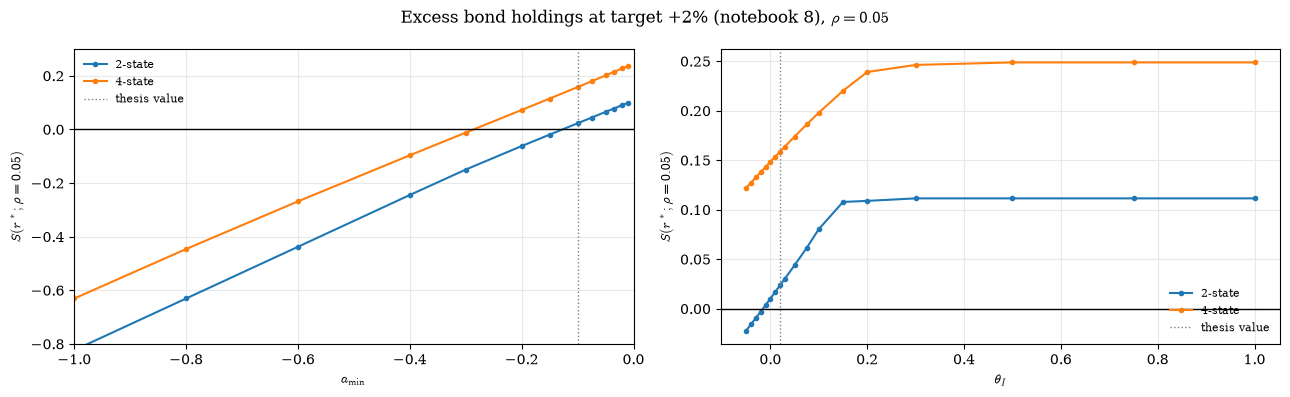

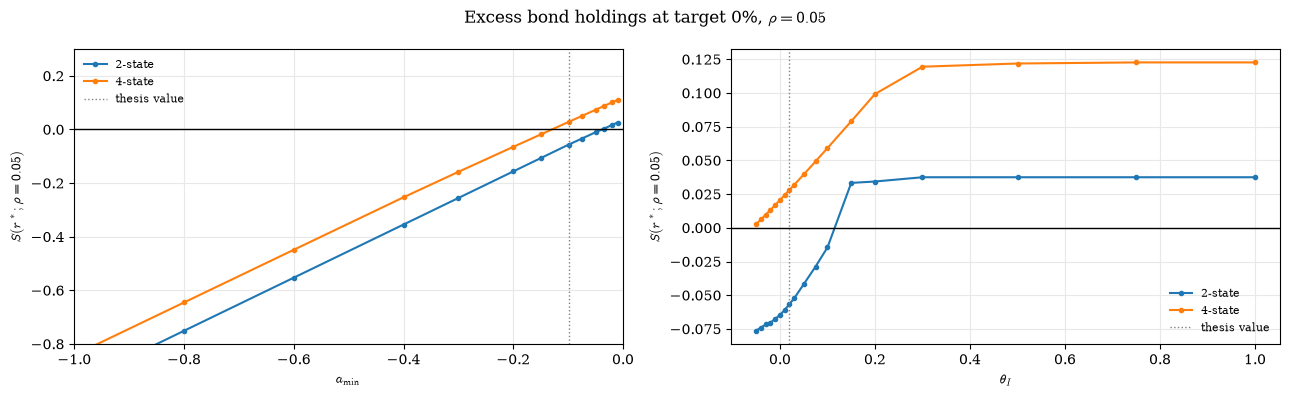

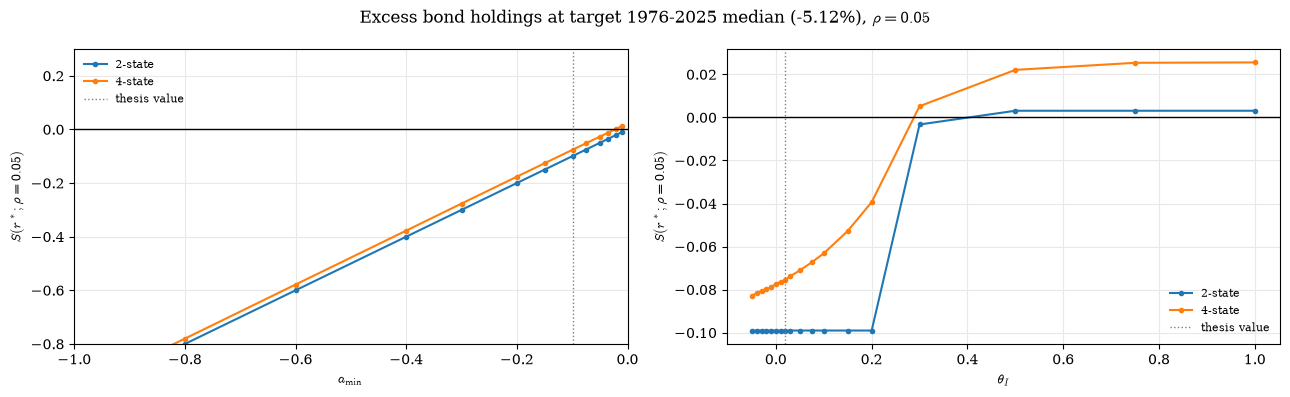

In [16]:
for lab in ("+2% (notebook 8)", "0%", [k for k in TARGETS if k.startswith("1976")][0]):
    plot_scans(scans_by_target[lab], rf"Excess bond holdings at target {lab}, $\rho=0.05$")


### Resolution check for tight borrowing limits

At negative targets the calibrated $a_{\min}$ is tight, and only a few grid points lie below zero. Re-calibrate those cases on a grid three times finer ($I=2400$). If $a_{\min}$ barely moves, the result is not an artefact of the grid.


In [17]:
def solve_with_amin_fine(r, m, amin, n_grid=2400):
    with borrowing_limit(amin, n_grid=n_grid):
        return solve_fixed(r, RHO_FIX, m)

res = []
for _, row in tab_free[(tab_free["free parameter"] == "a_min") & (tab_free["status"] == "ok")].iterrows():
    m = {"2-state": model_2state, "4-state": model_4state}[row["model"]](0.42); rt = row["r* target %"] / 100
    fine, st, _ = calibrate_scalar(lambda p: solve_with_amin_fine(rt, m, p), AMIN_GRID, tol=1e-5)
    res.append({"target": row["target"], "model": row["model"], "grid points below 0 (I=800)": row["grid points below 0"],
                "a_min, I=800": row["calibrated value"], "a_min, I=2400": fine,
                "relative change": fine / row["calibrated value"] - 1})
pd.DataFrame(res).round(4)


,target,model,grid points below 0 (I=800),"a_min, I=800","a_min, I=2400",relative change
0,+2% (notebook 8),2-state,20.0,-0.1271,-0.1274,0.0019
1,+2% (notebook 8),4-state,44.0,-0.2860,-0.2846,-0.0047
2,0%,2-state,6.0,-0.0377,-0.0390,0.0364
3,0%,4-state,21.0,-0.1296,-0.1294,-0.0014
4,-1%,2-state,4.0,-0.0191,-0.0206,0.0768
5,-1%,4-state,15.0,-0.0913,-0.0915,0.0015
6,-2%,4-state,11.0,-0.0653,-0.0655,0.0033
7,1993-2025 median (-3.56%),4-state,7.0,-0.0388,-0.0392,0.0094
8,1976-2025 median (-5.12%),4-state,4.0,-0.0227,-0.0235,0.0347


### Reading Step 5 (numbers from the tables above; $\rho=0.05$ throughout)

**1. Borrowing limit $a_{\min}$.**
- **2-state:** calibrates only for $r^*\ge -1\%$: $-0.038$ at $0\%$, $-0.019$ at $-1\%$ (0.7 and 0.4 months of income). For $r^*\le -2\%$ it is **not attainable**. Even at $a_{\min}=-0.01$, $S<0$: almost everyone sits at the limit, and no tighter limit can raise bond demand to zero.
- **4-state:** calibrates at every target. At the data medians, $a_{\min}=-0.039$ ($-3.56\%$) and $-0.023$ ($-5.12\%$), about 0.9 and 0.5 months of income. Gross debt / income is $0.03$ and $0.02$.
- The resolution check moves $a_{\min}$ by less than 4% in every case except the 2-state at $-1\%$ (8%, with only 4 grid points below zero). So these values are not grid artefacts.

**2. Informal premium $\theta_I$.**
- **4-state:** **not attainable for $r^*\ge 0$.** $S>0$ even with $\theta_I=-0.05$, the same mechanism as in notebook 8. For negative targets it needs $\theta_I = 0.042$ at $-1\%$, $0.127$ at $-2\%$, $0.228$ at $-3.56\%$ and $0.291$ at $-5.12\%$. The implied real informal borrowing rate $r+\theta_I$ is then $3\%$, $11\%$, $19\%$ and $24\%$.
- **2-state:** needs $\theta_I=-0.016$ at $+2\%$ (a negative premium), then $0.122$, $0.152$, $0.170$ and $0.235$ for $0\%$ to $-3.56\%$. That is a real informal borrowing rate of $12$–$20\%$.
- **2-state at $-5.12\%$: no robust equilibrium.** A root exists at fixed $r$ ($\theta_I=0.415$, a 36% real informal rate). But re-solving at that $\theta_I$ does not clear: $S(r)$ is flat at $-0.003$ over $r\in[-6.4\%,-5.4\%]$, and the solve fails at $-5.28\%$ (`cleared = False`). This is a knife-edge point, so treat it as not attainable.

**3. What the observable parameters say.**
- **Positive targets:** the 4-state model is the one needing an implausible observable parameter. It needs a very loose borrowing limit, and no informal premium works at all. The 2-state needs only a modest loosening of $a_{\min}$.
- **Negative targets (the ex-post data medians):** reversed. The 2-state cannot reach $r^*\le-2\%$ through $a_{\min}$, and through $\theta_I$ only with high premia, failing at $-5.12\%$. The 4-state reaches every target with a tight but positive borrowing limit, or with a real informal premium of about 20–30 points.
- The ranking of the models therefore again **depends on the target**, as with $\rho$ in Steps 2–4. The caveat in Step 4, point 5, about whether a negative ex-post peso rate is the right counterpart to $r^*$, applies unchanged.
- **Data that would decide it (not used here):**
  - for $\theta_I$: the spread between informal or non-bank consumer credit rates and the risk-free saving rate;
  - for $a_{\min}$: household debt / income and credit limits relative to wages (BCRA; Global Findex for the share of adults who borrow, formally and informally);
  - the borrower-share columns above are the matching untargeted model moments.


## Step 6. Summary figures: where is the 4-state model closer to the data?

**The hypothesis tested.** *The 4-state model is closer to reality*: it reaches the observed real rate with plausible parameter values, while the 2-state model needs strange ones. This step collects Steps 2 and 5 into two figures, for every target from $+2\%$ down to the 1976–2025 median.

**Pass rules** (set in the next cell, where they can be changed):
- $\rho$, free: the calibration exists and $\rho$ lies in the literature range $[0.02, 0.12]$.
- $a_{\min}$, free with $\rho=0.05$: a borrowing limit exists that clears the market at the target.
- $\theta_I$, free with $\rho=0.05$: a premium exists that clears the market (verified), and it is non-negative.

These rules only say whether a calibration is *possible and economically meaningful*. Whether the size of the required limit or premium is realistic is a data question. The first figure shows those sizes, and the cell defines `DEBT_INCOME_DATA` and `INFORMAL_PREMIUM_DATA`: set them to observed values to draw the data benchmark on the plots.


In [18]:
from matplotlib.patches import Rectangle
from matplotlib.transforms import blended_transform_factory

# ---- Plausibility rules used by the verdict (edit here; every figure below follows them) ----
RHO_RANGE = (0.02, 0.12)    # literature range for annual rho (Step 4 of notebook 8)
DEBT_INCOME_DATA = None     # observed household gross debt / income; set it to draw the benchmark
INFORMAL_PREMIUM_DATA = None  # observed spread of informal over safe real rates, percentage points

COL = {"2-state": "#2a78d6", "4-state": "#eb6834"}
INK, INK2, MUTED, GRID, AXIS, SURF, NEUTRAL = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
STYLE = {"font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "mathtext.fontset": "dejavusans",
         "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
         "axes.titleweight": "semibold", "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED,
         "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
         "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": SURF, "axes.facecolor": SURF,
         "legend.frameon": False, "text.color": INK, "lines.linewidth": 2, "lines.markersize": 7}

def passes(test, x):
    # One row of a calibration table -> does this model pass this test at this target?
    if x["status"] != "ok" or not x["cleared"] == True:
        return False
    if test == "rho":
        return RHO_RANGE[0] <= x["value"] <= RHO_RANGE[1]
    if test == "theta_I":
        return x["value"] >= 0                       # a negative premium is not economically meaningful
    return True                                      # a_min: attainable and the equilibrium clears

TESTS = {"rho": "Discount rate ρ\n(ρ free)", "a_min": "Borrowing limit $a_{min}$\n(ρ = 0.05)",
         "theta_I": "Informal premium $θ_I$\n(ρ = 0.05)"}
VERDICT = {(True, True): ("both pass", NEUTRAL, INK), (False, True): ("4-state only", COL["4-state"], "#ffffff"),
           (True, False): ("2-state only", COL["2-state"], "#ffffff"), (False, False): ("neither", "#ffffff", MUTED)}

def plot_verdicts(calib, target_labels, ax):
    # calib: long table with columns test, model, r* target %, value, status, cleared
    targets = sorted(calib["r* target %"].unique(), reverse=True)
    for i, test in enumerate(TESTS):
        for j, t in enumerate(targets):
            d = calib[(calib["test"] == test) & np.isclose(calib["r* target %"], t)].set_index("model")
            key = tuple(passes(test, d.loc[mn]) if mn in d.index else False for mn in ("2-state", "4-state"))
            text, face, ink = VERDICT[key]
            ax.add_patch(Rectangle((j + 0.03, -i - 0.97), 0.94, 0.94, facecolor=face,
                                   edgecolor=AXIS if face == "#ffffff" else face, lw=0.8))
            ax.text(j + 0.5, -i - 0.5, text, ha="center", va="center", color=ink, fontsize=9.5,
                    fontweight="semibold" if "only" in text else "normal")
    ax.set_xlim(0, len(targets)); ax.set_ylim(-len(TESTS), 0); ax.grid(False)
    ax.set_xticks(np.arange(len(targets)) + 0.5, [target_labels.get(t, f"{t:+.2f}%") for t in targets], fontsize=9)
    ax.set_yticks(-np.arange(len(TESTS)) - 0.5, list(TESTS.values()), fontsize=9.5, color=INK2)
    ax.tick_params(length=0); ax.xaxis.tick_top()
    for s in ax.spines.values(): s.set_visible(False)


In [19]:
# Long table: one row per (test, model, target), from Step 2 (rho) and Step 5 (a_min, theta_I)
calib = pd.concat([
    tab_neg.assign(test="rho").rename(columns={"rho": "value"}),
    tab_free.assign(test=tab_free["free parameter"]).rename(columns={"calibrated value": "value"}),
], ignore_index=True)
MEAN_INC = {mk(0.42)["name"]: (stationary(mk(0.42)["Lambda"]) * (1 - mk(0.42)["tau"]) * mk(0.42)["z"]).sum()
            for mk in (model_2state, model_4state)}
TARGET_LABELS = {100 * med_93: f"{100*med_93:.2f}%\n1993–2025\nmedian", 100 * med_50y: f"{100*med_50y:.2f}%\n1976–2025\nmedian",
                 2.0: "+2%\nadvisor", 0.0: "0%", -1.0: "−1%", -2.0: "−2%"}
calib.pivot_table(index=["test", "r* target %"], columns="model", values="value").sort_index(ascending=[True, False]).round(4)


model                2-state  4-state
test    r* target %                  
a_min    2.000000    -0.1271  -0.2860
         0.000000    -0.0377  -0.1296
        -1.000000    -0.0191  -0.0913
        -2.000000        NaN  -0.0653
        -3.562329        NaN  -0.0388
        -5.122232        NaN  -0.0227
rho      2.000000     0.0542   0.0780
         0.000000     0.0340   0.0577
        -1.000000     0.0240   0.0476
        -2.000000     0.0139   0.0375
        -3.562329        NaN   0.0217
        -5.122232        NaN   0.0059
theta_I  2.000000    -0.0156      NaN
         0.000000     0.1221      NaN
        -1.000000     0.1523   0.0423
        -2.000000     0.1701   0.1272
        -3.562329     0.2350   0.2275
        -5.122232     0.4153   0.2910

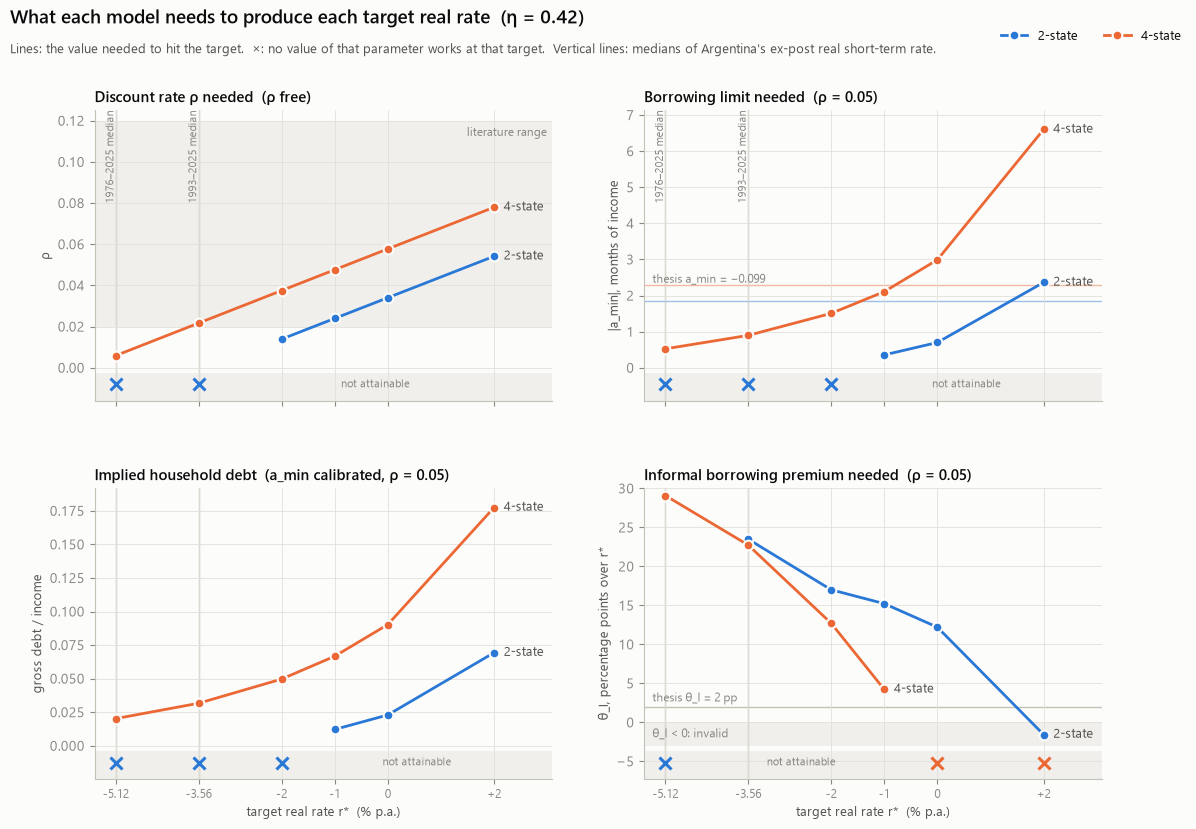

In [20]:
with plt.rc_context(STYLE):
    fig, axs = plt.subplots(2, 2, figsize=(13, 8.8), sharex=True)
    # (axis, test, column, scale, title, y label)
    panels = [(axs[0, 0], "rho", "value", 1, "Discount rate ρ needed  (ρ free)", "ρ"),
              (axs[0, 1], "a_min", "|a_min| in months of mean after-tax income", 1, "Borrowing limit needed  (ρ = 0.05)", "|a_min|, months of income"),
              (axs[1, 0], "a_min", "gross debt / income", 1, "Implied household debt  (a_min calibrated, ρ = 0.05)", "gross debt / income"),
              (axs[1, 1], "theta_I", "value", 100, "Informal borrowing premium needed  (ρ = 0.05)", "θ_I, percentage points over r*")]
    targets = sorted(calib["r* target %"].unique())
    for ax, test, col, scale, title, ylabel in panels:
        top = {"rho": 0.125, "theta_I": 30.0}.get(test, 1.08 * scale * calib.loc[calib["test"] == test, col].max())
        if test == "theta_I" and INFORMAL_PREMIUM_DATA is not None: top = max(top, INFORMAL_PREMIUM_DATA + 2)
        if test == "a_min" and col == "gross debt / income" and DEBT_INCOME_DATA is not None: top = max(top, 1.1 * DEBT_INCOME_DATA)
        bottom = -3.0 if test == "theta_I" else 0.0
        strip = bottom - 0.13 * (top - bottom)                    # "not attainable" strip below the data range
        ax.axhspan(strip, bottom - 0.02 * (top - bottom), color=NEUTRAL, zorder=0, lw=0)
        misses = []
        for mn in ("2-state", "4-state"):
            d = calib[(calib["test"] == test) & (calib["model"] == mn)].sort_values("r* target %")
            ok = (d["status"] == "ok") & (d["cleared"] == True)
            ax.plot(d.loc[ok, "r* target %"], scale * d.loc[ok, col], "o-", color=COL[mn], mec=SURF, mew=1.5, label=mn, zorder=3)
            miss = d.loc[~ok, "r* target %"]; misses += list(miss)
            ax.plot(miss, np.full(len(miss), 0.5 * (strip + bottom)), "x", color=COL[mn], ms=9, mew=2.2, zorder=3)
            last = d.loc[ok].iloc[-1]                              # direct label at the right-most point
            ax.annotate(mn, (last["r* target %"], scale * last[col]), xytext=(7, 0), textcoords="offset points",
                        color=INK2, fontsize=9, va="center")
        edges = sorted({targets[0] - 0.4, targets[-1] + 1.1, *misses})   # label the strip in its widest free gap
        gap = max(zip(edges, edges[1:]), key=lambda e: e[1] - e[0])
        ax.text(0.5 * sum(gap), 0.5 * (strip + bottom), "not attainable", color=MUTED, fontsize=8, ha="center", va="center")
        if test == "rho":
            ax.axhspan(*RHO_RANGE, color=NEUTRAL, zorder=0, lw=0)
            ax.text(targets[-1] + 1.05, RHO_RANGE[1] - 0.003, "literature range ", color=MUTED, fontsize=8.5, ha="right", va="top")
        elif test == "theta_I":
            ax.axhspan(bottom, 0, color=NEUTRAL, zorder=0, lw=0)
            ax.text(targets[0] - 0.3, -1.5, " θ_I < 0: invalid", color=MUTED, fontsize=8.5, ha="left", va="center")
            ax.axhline(2.0, color=AXIS, lw=1, zorder=1)
            ax.text(targets[0] - 0.3, 2.3, " thesis θ_I = 2 pp", color=MUTED, fontsize=8.5, va="bottom")
            if INFORMAL_PREMIUM_DATA is not None:
                ax.axhline(INFORMAL_PREMIUM_DATA, color=INK, lw=1.2)
                ax.text(targets[0] - 0.3, INFORMAL_PREMIUM_DATA, " data", va="bottom", fontsize=8.5)
        elif col.startswith("|a_min|"):
            for mn in ("2-state", "4-state"):
                ax.axhline(12 * -AMIN_THESIS / MEAN_INC[mn], color=COL[mn], lw=1, alpha=0.45, zorder=1)
            ax.text(targets[0] - 0.3, 12 * -AMIN_THESIS / MEAN_INC["4-state"], " thesis a_min = −0.099", color=MUTED,
                    fontsize=8.5, va="bottom")
        elif DEBT_INCOME_DATA is not None:
            ax.axhline(DEBT_INCOME_DATA, color=INK, lw=1.2)
            ax.text(targets[0] - 0.3, DEBT_INCOME_DATA, " data", va="bottom", fontsize=8.5)
        for t, lab in ((100 * med_93, "1993–2025 median"), (100 * med_50y, "1976–2025 median")):
            ax.axvline(t, color=AXIS, lw=1, zorder=0)
            if ax in axs[0]:
                ax.text(t, top, f" {lab}", color=MUTED, fontsize=8, rotation=90, ha="right", va="top")
        ax.set_ylim(strip, top); ax.set_title(title); ax.set_ylabel(ylabel, fontsize=9)
        ax.set_xlim(targets[0] - 0.4, targets[-1] + 1.1)
    for ax in axs[1]:
        ax.set_xlabel("target real rate r*  (% p.a.)", fontsize=9.5)
        ax.set_xticks(targets, [f"{t:+.2f}".rstrip("0").rstrip(".") if abs(t) > 1e-9 else "0" for t in targets], fontsize=8.5)
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(0.97, 0.975), ncol=2, fontsize=9.5)
    fig.suptitle("What each model needs to produce each target real rate  (η = 0.42)", x=0.06, ha="left",
                 fontsize=14, fontweight="semibold", y=0.985)
    fig.text(0.06, 0.935, "Lines: the value needed to hit the target.  ×: no value of that parameter works at that target.  "
             "Vertical lines: medians of Argentina's ex-post real short-term rate.", color=INK2, fontsize=9.5)
    fig.subplots_adjust(top=0.87, hspace=0.3, wspace=0.2)
    plt.show()


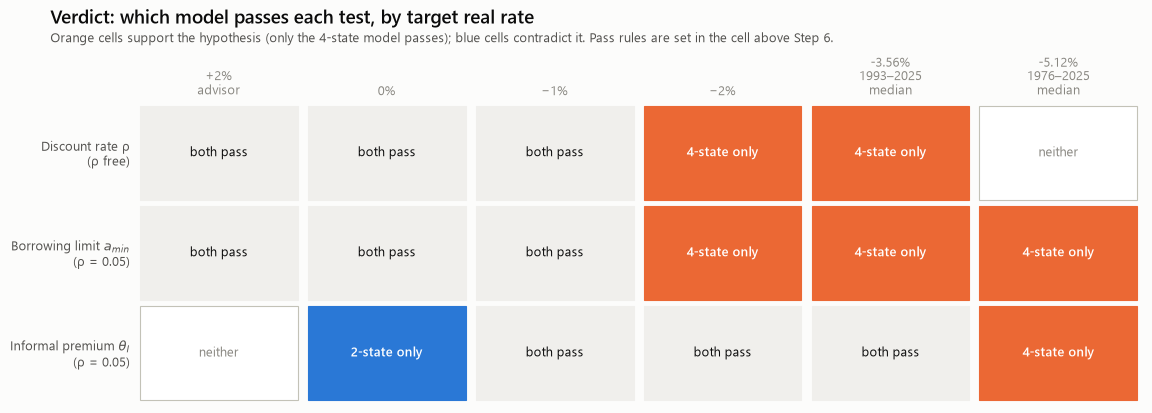

In [21]:
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(13, 3.9))
    plot_verdicts(calib, TARGET_LABELS, ax)
    fig.suptitle("Verdict: which model passes each test, by target real rate", x=0.06, ha="left",
                 fontsize=14, fontweight="semibold", y=1.12)
    fig.text(0.06, 1.035, "Orange cells support the hypothesis (only the 4-state model passes); blue cells contradict it. "
             "Pass rules are set in the cell above Step 6.", color=INK2, fontsize=9.5)
    plt.show()


### Reading Step 6: where the hypothesis holds

**It holds only for negative targets, and most clearly at the ex-post data medians.**

| Target | Evidence for "the 4-state model is closer to reality" |
|---|---|
| $+2\%$, $0\%$, $-1\%$ | **None.** Both models pass every test that either passes. At $0\%$ only the 2-state can be calibrated through $\theta_I$. At positive targets the 4-state needs a much looser borrowing limit and more household debt (first figure, right and lower-left panels). |
| $-2\%$ | **Partial.** Only the 4-state reaches it with $\rho$ in the literature range and with a borrowing limit; both can do it through $\theta_I$. |
| $-3.56\%$ (1993–2025 median) | **Yes, on $\rho$ and $a_{\min}$.** The 2-state needs $\rho<0$ or cannot reach it with any borrowing limit. Both reach it through $\theta_I$, with a premium of about 23 percentage points (a real informal borrowing rate of about 19–20%). |
| $-5.12\%$ (1976–2025 median) | **Yes, on $a_{\min}$ and $\theta_I$.** Only the 4-state reaches it. Neither model passes on $\rho$: the 4-state needs $\rho=0.006$, below the literature range. |

**What decides the question is therefore the choice of target, not the models.**
- If the right counterpart to $r^*$ is a **positive** real rate, the advisor's $+2\%$ or a dollar-based return near $0$–$1\%$, the hypothesis is **not supported**.
- If it is the **negative ex-post peso rate**, the hypothesis is **supported**: the 4-state model is the only one that matches it with a positive discount rate and an admissible borrowing limit.
- Step 4, point 5, above gives the reasons to doubt that the negative ex-post rate is the right counterpart.

**What would strengthen either conclusion.** The tests above check whether a calibration is possible. To check whether it is realistic, set `DEBT_INCOME_DATA` (household gross debt / income) and `INFORMAL_PREMIUM_DATA` (spread of informal over safe borrowing rates, pp) to observed values. The first figure then shows directly which model's requirement is closer to the data.
